In [52]:
# Import of the necessary python libraries
import pandas as pd
import pandas_datareader as pdr
import pandas_datareader.data as web
import numpy as np
import scipy.stats as scs
import matplotlib.pyplot as plt

In [53]:
# Define the risk-free rate rf for the calculation (for calculation of rf see the Excel tables)
rf = 0.0509

In [54]:
prices = pd.read_csv('BRICS_L_M_S_CORONA.csv', delimiter=';',decimal=',', thousands="." , skip_blank_lines=True , index_col=0, parse_dates=True, infer_datetime_format=True)
prices.head()

/tmp/ipykernel_1360/450694028.py:1: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  prices = pd.read_csv('BRICS_L_M_S_CORONA.csv', delimiter=';',decimal=',', thousands="." , skip_blank_lines=True , index_col=0, parse_dates=True, infer_datetime_format=True)


,Large Cap,Mid Cap,Small Cap
Date,,,
01.10.2019,12022.18,2392.28,1778.33
02.10.2019,11954.65,2367.52,1767.25
03.10.2019,12014.23,2375.83,1772.28
04.10.2019,11999.71,2387.97,1771.04
07.10.2019,11955.71,2367.04,1758.53


In [55]:
# Convert dates to a proper datetime index
prices.index = pd.to_datetime(
    prices.index,
    dayfirst=True
)

# Sort observations chronologically
prices = prices.sort_index()

# Annualized expected returns using trading days
trading_days = 250

daily_returns = prices.pct_change(
    fill_method=None
).dropna()

e_r = daily_returns.mean() * trading_days

e_r



,0
Large Cap,0.152159
Mid Cap,0.142861
Small Cap,-0.012067


In [56]:
# Covariance of daily simple returns
cov_matrix = daily_returns.cov()
cov_matrix


,Large Cap,Mid Cap,Small Cap
Large Cap,0.000220,0.000233,0.000226
Mid Cap,0.000233,0.000289,0.000277
Small Cap,0.000226,0.000277,0.000293


In [57]:
# Annualized volatility using the same daily returns
sd = daily_returns.std() * np.sqrt(trading_days)
sd

,0
Large Cap,0.234544
Mid Cap,0.268982
Small Cap,0.270806


In [58]:
# Concatenation of the indices and the returns/volatility
assets = pd.concat([e_r, sd], axis=1)
assets.columns = ["Returns", "Volatility"]
assets

,Returns,Volatility
Large Cap,0.152159,0.234544
Mid Cap,0.142861,0.268982
Small Cap,-0.012067,0.270806


In [59]:
# Creating blanco lists for the portfolio return, portfolio volatility and the weights of the particular indices
# In addition, setting the number of determined portfolios to 2500 --> Law of large numbers
p_ret = []
p_vol = []
p_weights = []

num_assets = len(prices.columns)
num_portfolios = 2500

In [60]:
# Calculation of the weights of the particular indices by frequently random
np.random.seed(42)

for portfolio in range(num_portfolios):
    weights = np.random.random(num_assets)
    weights = weights/np.sum(weights)
    p_weights.append(weights)
    returns = np.dot(weights, e_r)
    p_ret.append(returns)
    var = cov_matrix.mul(weights, axis=0).mul(weights, axis=1).sum().sum()
    sd = np.sqrt(var)
    ann_sd = sd*np.sqrt(trading_days)
    p_vol.append(ann_sd)

In [61]:
# Return and Volatility Variables for plotting the portfolios
port_ret = np.array(p_ret)
port_vol = np.array(p_vol)

In [62]:
data = {"Returns": p_ret, "Volatility": p_vol}

In [63]:
for counter, symbol in enumerate(prices.columns.tolist()):
    data[symbol+" weight"] = [w[counter] for w in p_weights]

In [64]:
portfolios = pd.DataFrame(data)

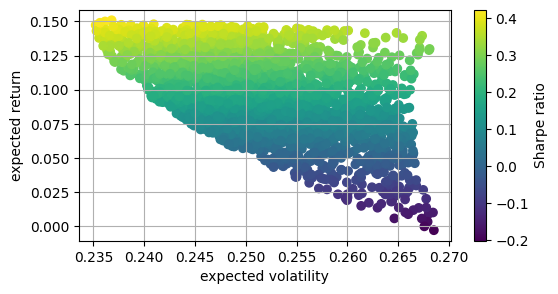

In [65]:
# Plotting the 2500 calculated portfolios and the Sharpe ratio in the colorbar
plt.figure(figsize=(6, 3))
plt.scatter(port_vol, port_ret, c=(port_ret-rf)/port_vol, marker='o')
plt.grid(True)
plt.xlabel('expected volatility')
plt.ylabel('expected return')
plt.colorbar(label='Sharpe ratio')

In [66]:
# Summary of the MVP with Return, Volatility and the particular weights
min_var_port = portfolios.iloc[portfolios["Volatility"].idxmin()]
min_var_port

,400
Returns,0.147361
Volatility,0.235233
Large Cap weight,0.941973
Mid Cap weight,0.030544
Small Cap weight,0.027484


In [67]:
sharpe_ratio_mvp = (min_var_port["Returns"] - rf) / min_var_port["Volatility"]
sharpe_ratio_mvp

np.float64(0.4100656137605463)

In [68]:

print("First date:", prices.index.min())
print("Last date:", prices.index.max())
print("Price observations:", len(prices))
print("Return observations:", len(daily_returns))
print("Dates sorted:", prices.index.is_monotonic_increasing)


First date: 2019-10-01 00:00:00
Last date: 2020-06-18 00:00:00
Price observations: 181
Return observations: 180
Dates sorted: True


/tmp/ipykernel_1360/1572838316.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.scatter(min_var_port[1], min_var_port[0], color="r")


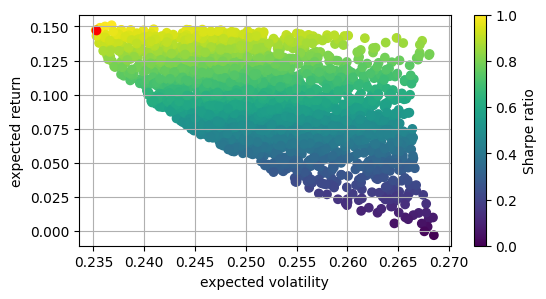

In [69]:
# Visualization of the MVP into the portfolio figure with a red point
plt.subplots(figsize=(6,3))
plt.scatter(portfolios["Volatility"], portfolios["Returns"], c = (portfolios["Returns"]-rf)/portfolios["Volatility"])
plt.scatter(min_var_port[1], min_var_port[0], color="r")
plt.grid(True)
plt.xlabel('expected volatility')
plt.ylabel('expected return')
plt.colorbar(label='Sharpe ratio')

In [70]:
# The portfolio with the maximum sharpe ratio is saved in the variable optimal_risky_portfolio and the summary is shown below
optimal_risky_portfolio = portfolios.iloc[((portfolios["Returns"]-rf)/portfolios["Volatility"]).idxmax()]
optimal_risky_portfolio

,1383
Returns,0.150929
Volatility,0.236802
Large Cap weight,0.868330
Mid Cap weight,0.131636
Small Cap weight,0.000034


In [71]:
sharpe_ratio = (optimal_risky_portfolio["Returns"] - rf) / optimal_risky_portfolio["Volatility"]
sharpe_ratio

np.float64(0.4224165091011537)

/tmp/ipykernel_1360/2552339649.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.scatter(min_var_port[1], min_var_port[0], color="r")
/tmp/ipykernel_1360/2552339649.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.scatter(optimal_risky_portfolio[1], optimal_risky_portfolio[0], color="b")


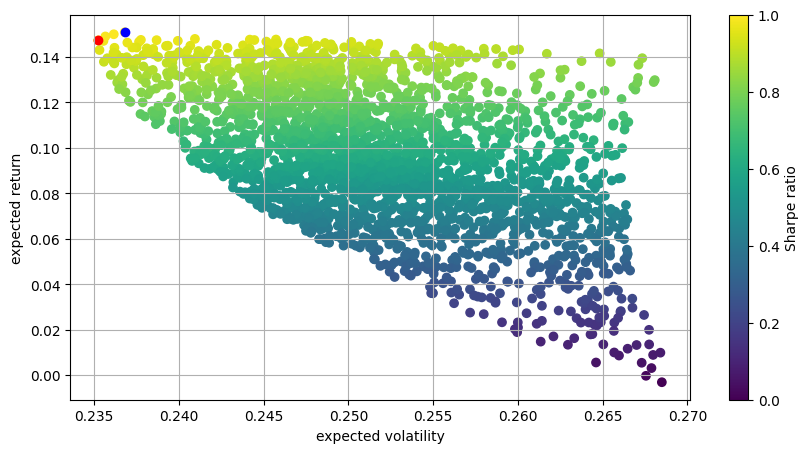

In [72]:
# Visualization of the optimal risky portfolio into the previous figure with a blue point
plt.subplots(figsize=(10,5))
plt.scatter(portfolios["Volatility"], portfolios["Returns"], c = (portfolios["Returns"]-rf)/portfolios["Volatility"])
plt.scatter(min_var_port[1], min_var_port[0], color="r")
plt.scatter(optimal_risky_portfolio[1], optimal_risky_portfolio[0], color="b")
plt.grid(True)
plt.xlabel('expected volatility')
plt.ylabel('expected return')
plt.colorbar(label='Sharpe ratio')
# Safe the figure to the computer (optional)
plt.savefig("port_emerg_covid.png", dpi=300, bbox_inches="tight")

In [73]:

# Final validation of portfolio calculations
print("=== Emerging Markets COVID — Validation ===")

print("\nRisk-free rate:", rf)
print("Annualization factor:", trading_days)
print("Number of simulated portfolios:", len(portfolios))

print("\nMaximum-Sharpe portfolio:")
print(optimal_risky_portfolio)

print("\nMinimum-variance portfolio:")
print(min_var_port)

print("\nSharpe ratio:")
print((optimal_risky_portfolio["Returns"] - rf) /
      optimal_risky_portfolio["Volatility"])

weight_columns = [
    col for col in portfolios.columns
    if col.endswith(" weight")
]

print("\nSum of maximum-Sharpe portfolio weights:")
print(optimal_risky_portfolio[weight_columns].sum())

print("\nSum of minimum-variance portfolio weights:")
print(min_var_port[weight_columns].sum())

print("\nMissing values in daily returns:")
print(daily_returns.isna().sum().sum())


=== Emerging Markets COVID — Validation ===

Risk-free rate: 0.0509
Annualization factor: 250
Number of simulated portfolios: 2500

Maximum-Sharpe portfolio:
Returns             0.150929
Volatility          0.236802
Large Cap weight    0.868330
Mid Cap weight      0.131636
Small Cap weight    0.000034
Name: 1383, dtype: float64

Minimum-variance portfolio:
Returns             0.147361
Volatility          0.235233
Large Cap weight    0.941973
Mid Cap weight      0.030544
Small Cap weight    0.027484
Name: 400, dtype: float64

Sharpe ratio:
0.4224165091011537

Sum of maximum-Sharpe portfolio weights:
1.0

Sum of minimum-variance portfolio weights:
1.0

Missing values in daily returns:
0
